# Lab 4 - Monte Carlo Control in Blackjack game

## 1. Objectives

In this lab, we will:

1. Understand how Monte Carlo methods can be used to estimate value functions from experience, without knowing the transition probabilities of the environment.

2. Model the Blackjack game as an episodic Markov Decision Process (MDP) with terminal rewards.

3. Implement first-visit Monte Carlo policy evaluation to estimate state-value and action-value functions.

4. Apply Monte Carlo control to learn an optimal policy for Blackjack.

5. Address the exploration problem by using exploring starts and $\varepsilon$-soft policies.

6. Study off-policy Monte Carlo learning and understand how a target policy can be evaluated using data generated by a different behavior policy. Implement importance sampling (ordinary and weighted) to correct the distribution mismatch in off-policy learning.

-------------------

## 2. Blackjack game

Blackjack is a card game played between a **player** and a **dealer**. The goal is to obtain a hand value as close as possible to 21, without exceeding it.

- Card values
    - Number cards (2–10): face value
    - Face cards (J, Q, K): value 10
    - Ace (A): value 1 or 11
        - The Ace (A) is a special card in Blackjack because it can take two possible values: 1 or 11.
        - When an Ace is counted as 11 without making the hand exceed 21, we say the hand has a usable ace.
        - If counting the Ace as 11 would cause the total to exceed 21, the Ace is automatically counted as 1.
        - This choice is not an action taken by the player; it is an automatic rule of the game that always favors avoiding a bust.


- Game flow
    - The game starts by giving the player an initial hand and showing one visible card for the dealer.
        - The player then plays first and repeatedly chooses between:
            - **Hit**: draw one additional card
            - **Stick**: stop drawing cards
        - If the player’s total exceeds 21 at any time, the episode ends immediately with a loss.
        - After the player sticks, the dealer plays:
            - The dealer must hit until the hand value is at least 17
            - Then the dealer sticks

- Outcome and rewards
   - Player wins if their final hand value is higher than the dealer’s without busting.
   - Player loses if they bust or if the dealer has a higher hand.
   - A draw (tie) gives zero reward.

**Next, we will model the Blackjack game as an episodic Markov Decision Process (MDP) with terminal rewards.**

### 2.0 Imports and global settings

In [ ]:
import numpy as np
from collections import defaultdict
import matplotlib.pyplot as plt

# Reproducibility
rng = np.random.default_rng(0)

### 2.1 Blackjack environment (State, Action, Episode, Rewards)

1. State is a summary of the game
$$
s=(p,d,u)
$$
where
    - $p =$ player's current sum
    - $d =$ dealer’s showing card (1–10)
    - $u =$ usable ace indicator (0/1)

  
2. Player's action :
    - STICK = 0
    - HIT = 1
      
3. Episode ends when:
    - player busts (sum > 21), or
    - player sticks and dealer finishes their fixed policy (hit until 17)

4. Rewards:
    - player bust: −1
    - else at terminal after dealer plays: win +1, lose −1, draw 0
    - Here, intermediate rewards are 0; only terminal reward matters.

5. Uniform card draws: Here in this lab, we assume a uniform draw of cards to simplify the environment and preserve the Markov property.
    - With uniform draws: future cards are independent of the past; the state $(p,d,u)$ is sufficient.
    - With a real deck: card probabilities depend on the history of drawn cards; therefore, the state $(p,d,u)$ is no longer Markov.

In [ ]:
# In Blackjack the player has two possible decisions:
STICK = 0  # STICK: stop drawing cards (end the player’s turn)
HIT = 1 # HIT: draw one more card
ACTIONS = [STICK, HIT] # the list of all valid actions

We now define a function that draws a card with a value in $\{1,2,\cdots,10\}$.
    
1. The value 1 represents an Ace.
2. The value 10 represents any 10, Jack, Queen, or King, all of which are treated as having value 10.

**Important** To simplify the environment and make it suitable for modeling as a Markov Decision Process (MDP), we assume that cards are drawn uniformly from this set. This removes the need to track the remaining deck composition and allows the transition dynamics to depend only on the current state.

In [ ]:
# Uniform card drawing (simplified version), see Point 5 above.

def draw_card(rng): # rng is a random number generator (typically np.random.default_rng(seed)).
    """
    Draw a card value in {1,...,10}.
    (Simplified Blackjack: uniform draw in 1..10)
    """
    return int(rng.integers(1, 11)) # rng.integers(1, 11) draws a random integer in [1, 10] (upper bound 11 is excluded).


Now we define a function `usable_ace(hand)` to detect whether an Ace in hand can be trated as “11”, which means, it is a usable ace.

Recall that a “usable ace” means: the hand contains an Ace (1 in hand) and we can treat that Ace as 11 instead of 1 without going over 21.

Examples:
- hand = [1, 7] $\rightarrow$ sum(hand)=8 $\rightarrow$ 8+10=18 <= 21 $\rightarrow$ usable ace = True
- hand = [1, 7, 5] $\rightarrow$ sum=13 $\rightarrow$ 13+10=23 > 21 $\rightarrow$ usable ace = False (Here ace must be counted as 1)


In [ ]:
def usable_ace(hand): # hand is a Python list of card values, e.g. [1, 7] or [10, 6, 2].
    """
    Returns True if hand has an ace (value 1) that can be counted as 11
    without busting.
    """
    return (1 in hand) and (sum(hand) + 10 <= 21) # Recall that the Ace is stored as 1; sum(hand) is defined below.


This `sum_hand(hand)` function returns the hand’s effective score under Blackjack rules:

1. If there is a usable ace, count one ace as 11 (add 10).
2. Otherwise, just return the raw sum.

Why “best” sum? Since Blackjack players always prefer the highest total $\leq$ 21.


In [ ]:
def sum_hand(hand): # this function computes the best total
    """
    Return best (highest) sum <=21 if possible by counting usable ace as 11.
    Otherwise return the raw sum.
    """
    s = sum(hand)
    if usable_ace(hand):
        return s + 10
    return s

Now we define `is_bust(hand)` function to check if we exceed 21.

In [ ]:
def is_bust(hand):
    """True if hand sum exceeds 21."""
    return sum_hand(hand) > 21

Now we define `score(hand)` for the terminal “value” of a hand. It returns a “hand score” used at the end of a game:

1. If bust: score = 0 (player is effectively dead)
2. Else: score = effective sum

In [ ]:
def score(hand):
    """
    Terminal score:
    - 0 if bust
    - else sum_hand
    """
    return 0 if is_bust(hand) else sum_hand(hand)

Now we define `initial_hands(rng)` to start a new episode (Environment reset).

It creates the initial state of a Blackjack episode:

- player starts with 2 cards

- dealer starts with 2 cards

The environment internally keeps both dealer cards, but the agent will only observe one (typical Blackjack rule: one dealer card is face-up).

In [ ]:
def initial_hands(rng):
    """
    Start of a Blackjack episode:
    - Player draws 2 cards
    - Dealer draws 2 cards, but we only "observe" dealer[0]
    """
    player = [draw_card(rng), draw_card(rng)]
    dealer = [draw_card(rng), draw_card(rng)]
    return player, dealer

Now we define the state representation for the player, which is the RL agent.

We convert the full hands (lists of cards) into a state tuple $(p, d, u)$, where

1. `p = sum_hand(player)`, which is Player’s current total under Blackjack rules (Ace possibly counted as 11).
2. `d = dealer[0]`, which is Dealer’s visible card (the one face-up).
3. `u = int(usable_ace(player))`, which is a binary feature : 1 if the player has a usable ace; 0 otherwise


In [ ]:
def obs(player, dealer): # obs for observation
    """
    Convert internal hands into tabular state (p, d, u)
    - p: player sum
    - d: dealer showing (1..10)
    - u: usable ace flag (0/1)
    """
    p = sum_hand(player)
    d = dealer[0]  # dealer showing card
    u = int(usable_ace(player))
    return (p, d, u)

### 2.2 Blackjack step function

In reinforcement learning, an environment step function typically implements:
$$
(S_{t+1}, r_{t+1}, \text{done})=\text{step}(s_t, a_t)
$$
where
1. the input are the current state (here: `(player, dealer)`) and an action `(HIT or STICK)`;
2. and the output are the updated state `(player, dealer)`; the reward for this transition and a boolean `done` indicating whether the episode ended.

In Blackjack,
1. If the player hits, the game may continue (unless the player busts).
2. If the player sticks, the dealer finishes playing, and the episode ends immediately.

In [ ]:
def step(player, dealer, action, rng):
    """
    Take action from current state.
    The input are

    player: list of the player's current cards, e.g. [10, 6]

    dealer: list of the dealer's current cards, e.g. [1, 7]

    action:
        HIT (1): player draws one card
        STICK (0): player stops; dealer plays out; episode ends

    rng: random generator used to draw cards

    and the Returns are (player, dealer), reward, done (explained later)
    """
    if action == HIT:                         # Case 1: Player chooses HIT
        player.append(draw_card(rng))         # If the player hits, we draw a new random card using draw_card(rng)
                                              # append(...) modifies the player list in-place by adding that new card.

        if is_bust(player):                     # if Player bust -> immediate terminal with reward -1
            return (player, dealer), -1, True   # if Player bust, the episode terminates immediately (done = True)
        else:                                   # else, the game is not finished (done = False); no intermediate reward
            return (player, dealer), 0, False   # reward is 0 since Blackjack gives reward only at the end: win = +1, lose = −1, draw = 0
                                                # While the game is still ongoing, we give no intermediate reward,

    # Case 2: Player chooses STICK (action == STICK) : then Player stops drawing cards.
    # Now the dealer plays according to a fixed policy: Dealer must hit while total < 17 Dealer sticks once total is ≥ 17
    # This is a simplified Blackjack dealer behavior used in Sutton & Barto’s Blackjack example.

    while sum_hand(dealer) < 17:                # This loop will draw cards for the dealer, until the stopping condition is met.
        dealer.append(draw_card(rng))           # It modifies dealer in-place.


    # Compute terminal “scores”: Recall score(hand) returns: 0 if bust ; otherwise the hand sum (with usable ace adjustment)

    ps = score(player)                          # player terminal score
    ds = score(dealer)                          # dealer terminal score

    # Decide win/lose/draw and reward
    # The player wins if: dealer busts (dealer total > 21 i.e. score(dealer)==0), or player’s score is strictly higher than dealer’s score
    if ds == 0 or ps > ds:
        reward = 1
    elif ps < ds:  # Player loses if their score is strictly less than dealer’s score.
        reward = -1
    else:
        reward = 0 # Otherwise, the only remaining case is ps == ds, a tie.


# Return terminal transition:

# After STICK, the dealer has finished playing and we have compared results.
# Therefore the episode ends: done=True.
# Reward is one of {+1, 0, −1}.
# We return the final hands as the terminal state.

    return (player, dealer), reward, True

# The Return values are:

# (player, dealer): new state
# reward: numeric reward (−1, 0, +1)
# done: whether the episode ended

-------------------

## 3. First-visit Monte Carlo method to estimate state-value functions

### 3.1 Episode generation (core for Monte Carlo)

Monte Carlo methods learn from complete episodes.
So we need a function that:

1. starts a new game,

2. follows a policy to generate $(S_t, A_t)$ pairs until terminal,

3. returns the whole episode + terminal reward.



**Exercise 1.** Write a function `generate_episode` that simulates one complete Blackjack game (one episode) using a input policy.
The inputs of this function `generate_episode` are
1. `policy_fn` the input policy, which is a function that takes a state $s$ and returns an action: `HIT` (1) or `STICK` (0)
2. `rng`, which is a random generator for drawing cards (so results are reproducible).

The outputs of this function `generate_episode` are
1. `episode`: which is a list like $[(S_0, A_0), (S_1, A_1), ..., (S_{T-1}, A_{T-1})]$
2. `G`, which is the terminal return (final reward) in $\{-1, 0,1\}$ (lose, draw, win) since in our simplified Blackjack: intermediate rewards are 0, only the final outcome matters.

*Remark.* In Blackjack, not all states are equally important for decision-making. When the player’s sum is below 12, hitting is always safe, since even the largest possible card (value 10) cannot make the player bust.

As a result, there is no real choice to make in these states, and the player should always hit. For this reason, we simplify the problem by: forcing the action HIT when the player’s sum $p<12$,and only learning decisions for states with $p=12,…,21$.

This reduces the number of states we need to consider, speeds up learning, and does not change the optimal behavior.

In [ ]:
# Exercise 1. Complete the TO DO part

def generate_episode(policy_fn, rng):
    """
    Generate one full episode following a given policy.

    Hint:
    - An episode is a complete Blackjack game.
    - You should repeatedly:
        1) observe the current state,
        2) choose an action using the policy,
        3) apply the action to the environment,
        4) stop when the game ends.

    Returns:
        episode: list of (state, action) pairs
        G: terminal return (final reward), in {-1, 0, 1}
    """

    # 1. Initialize a new game by dealing cards to player and dealer
    player, dealer = initial_hands(rng)

    # 2. Create an empty list to store the trajectory
    episode = []

    # 3. Simulate the game until a terminal state is reached
    while True: # # Blackjack episode length is not fixed. We keep looping until the game ends (terminal state).

        # 3.a Observe the current state (player sum, dealer showing card, usable ace)
        s = obs(player, dealer)

        # 3.b Choose an action
        # Hint:
        # - s[0] is the player's current sum
        # - if the sum is less than 12, hitting is always safe
        # - otherwise, use the policy function

        if s[0] < 12:
            a = 1          # choose HIT
        else:
            a = policy_fn(s)         # choose action according to policy_fn

        # 3.c Record the state–action pair
        episode.append((s, a))

        # 3.d Apply the action to the environment
        # Hint:
        # - step returns (new_player, new_dealer), reward, and done flag
        (player, dealer), r, done = step(player, dealer, a, rng)

        # 3.e If the episode is finished, return the trajectory and the final reward
        if done: # Why here we write directly if done ?
            # Hint:
            # - all intermediate rewards are zero
            # - the return G equals the terminal reward r
            return episode, r


Test your `generate_episode` function with the following `always_hit_policy` :).

In [ ]:
# check generate_episode

def always_hit_policy(state):
    return HIT

episode, G = generate_episode(always_hit_policy, rng)

print("Episode length:", len(episode))
print("Terminal return G:", G)
print("First 3 steps:", episode[:3])


Episode length: 3
Terminal return G: -1
First 3 steps: [((16, 6, 0), 1), ((20, 6, 0), 1), ((21, 6, 0), 1)]


### 3.2 Estimates the state-value function of a fixed policy $\pi$ using Monte-Carlo



In this section, we estimate the **state-value function** of a **fixed policy** using **first-visit Monte Carlo methods**.

The goal is to approximate, for each state $s$,
$$
V_\pi(s) = \mathbb{E}_\pi[G \mid S_t = s],
$$
that is, the expected final reward obtained when starting from state $s$ and following the policy $\pi$.

**Key ideas**

- We generate many **complete episodes** (full Blackjack games) by following a fixed policy.
- Each episode ends with a **terminal reward** $G \in \{-1, 0, 1\}$.
- For a given state $s$, we use the observed return $G$ as a **sample** of $V_\pi(s)$.
- In **first-visit Monte Carlo**, each state is updated **only the first time it appears in an episode**.
- The value $V_{\pi}(s)$ is estimated by the **average of all observed returns** from first visits to $s$.

**Important remarks**

- This method does not require transition probabilities.
- Updates are performed **only after an episode terminates**.
- In our Blackjack setting, all intermediate rewards are zero, so the return is simply the terminal reward. Hence, we do not code it backward because, in this Blackjack setting, the return is the same for all time steps, so a backward pass brings no benefit. A forward pass is simpler and equivalent.


**Exercise 2.** Define a `mc_prediction_first_visit()` function to estimates the state-value function of a fixed given policy $\pi$.

Recall that in the simplified setting of Blackjack that we use  in this lab: rewards are 0 during the game, only the terminal reward is nonzero, so the return $G$ is just the final outcome in {−1,0,1}. And Monte Carlo prediction approximates the expectation by averaging returns from many episodes.

The inputs of `mc_prediction_first_visit()` are
1. `num_episodes`: Number of complete Blackjack games (episodes) to simulate. Each episode is one full game, from the initial deal until the game ends. Monte Carlo methods estimate expectations by averaging over many episodes.
A larger num_episodes gives: more accurate estimates of the value function, but higher computational cost.

2. `rng`: random number generator, which is the source of randomness used to simulate the environment.

The output of `mc_prediction_first_visit()` is

`V` a dictionary mapping each state $s$ to an estimate of $V_{\pi}(s)$.

A example of type `dict`:

In [ ]:
grades = {
    "Alice": 15,
    "Bob": 12,
    "Charlie": 18
}
print (grades["Alice"])   # returns 15

15


In [ ]:
# Exercise 2. Complete the TO DO part


def mc_prediction_first_visit(num_episodes=200_000, rng=rng):
    """
    First-visit Monte Carlo prediction for a fixed policy.

    Goal:
    - Estimate the state-value function V(s) of a given policy.
    - Use first-visit Monte Carlo: each state is updated at most once per episode.

    Returns:
        V: dict mapping state -> estimated value
    """

    # 1. Initialize the value function and statistics

    # Hint:
    # - V[s] should store the estimated value of state s
    # - For Monte Carlo averaging, we need to keep:
    #     * the sum of observed returns for each state
    #     * the number of times each state has been updated
    V = defaultdict(float)         # This creates an empty dictionary where V[s] is the estimated value of state s,
                                   # defaultdict(float) means unseen keys default to 0.0

    # For each state s, we store:
    returns_sum = defaultdict(float)  # sum of all returns observed from episodes where we first-visited s
    returns_count = defaultdict(int)  # number of times s was first-visited
    # then V[s]=returns_sum[s]/returns_count[s]

    # 2. Define the policy to be evaluated

    def pi(s): # This defines a local policy function pi. Because generate_episode expects a function policy_fn(state) -> action
               # we want to evaluate the fixed policy called target_policy, which is defined outside the function.
        return target_policy(s) # We use pi(s) for clarity, to distinguish the evaluated policy from other policies (but it is not necessary)

    # 3. Main Monte Carlo loop

    # Hint:
    # - Each iteration corresponds to one complete episode (one full Blackjack game)
    for _ in range(num_episodes):

        # 3.a Generate one episode following policy pi
        # episode: list of (state, action)
        # G: terminal return in {-1, 0, 1}
        episode, G = generate_episode(pi,rng) # Hint. see Exercise 1 generate_episode().

        # 3.b Keep track of states already visited in this episode
        visited_states = set() # this is an empty set to store the visited_states in the future.

        # 3.c Loop over all state–action pairs in the episode
        for (s, a) in episode:

            # Extract state components
            p, d, u = s

            # 3.c.i Ignore states with player sum < 12
            # Hint:
            # - These are not treated as decision states
            if p < 12:
                continue

            # First-visit condition
            # Hint:
            # - Update the value of s only if it has not appeared
            #   earlier in the same episode
            if s not in visited_states:

                visited_states.add(s) # TODO: add state s to visited_states. Hint. set_name.add(s)


                # Update Monte Carlo statistics
                # Hint:
                # - The return G is the same for all states in this episode
                returns_sum[s] += G # TODO: update returns_sum[s], add the new retrun G
                returns_count[s] += 1 # TODO: update returns_count[s], add one


                # Update the value estimate V(s)
                # Hint:
                # - Use the sample-average formula
                #     V(s) = (sum of returns) / (number of returns)
                V[s] = returns_sum[s]/returns_count[s] # TODO: update V[s]


    # 4. Return the estimated value function
    return V


Now we check if `mc_prediction_first_visit` is correctly defined.

In [ ]:
# check mc_prediction_first_visit

def target_policy(state):
    """
    Deterministic policy:
      - HIT if player's sum < 20
      - else STICK
    """
    p, d, u = state
    return HIT if p < 20 else STICK

# Appel de la fonction corrigée
V = mc_prediction_first_visit(num_episodes=10000, rng=rng)
print(type(V), len(V))

s_test = (20, 10, 0)
print(V[s_test])

<class 'collections.defaultdict'> 200
0.6234567901234568


--------------------------------

## 4. Apply Monte Carlo control to learn an optimal policy for Blackjack (with exploring starts).

In this section, we move from **policy evaluation** to **policy control**.

Our goal is no longer to evaluate a fixed policy, but to **learn an (approximately) optimal policy** for Blackjack directly from experience. To do this, we use **Monte Carlo control with exploring starts**.

### Key ideas

- We estimate the **action-value function** $Q(s,a)$, which represents the expected final reward when taking action $a$ in state $s$.
- We generate many complete episodes (full Blackjack games).
- After each episode, we update $Q(s,a)$ using the observed return.
- We then **improve the policy greedily** by choosing, in each state, the action with the highest estimated $Q$-value.
- **Exploring starts** ensure that different state–action pairs are tried, by forcing the first action of each episode to be random.

This approach alternates between **evaluation** (updating $Q$) and **improvement** (updating the policy), gradually converging toward an optimal strategy.

> **This exercise is more challenging than the previous ones.**  
> It combines several ideas at once (episodes, first-visit Monte Carlo, action-values, and policy improvement).  
> **Do not be discouraged if it does not work immediately**: take it step by step, follow the hints, and focus on understanding the logic rather than writing everything at once.


**Exercise 3 ($\star$).** Write a `mc_control_exploring_starts` function that learns an (approximately) optimal policy for Blackjack by iterating:

1. Generate an episode using the current policy (with exploring starts)
2. Compute the return $G$ (here it’s just the terminal reward)
3. Update the action-value function $Q(s,a)$ using sample averages
4. Improve the policy to be greedy w.r.t. the updated $Q$.

Remark. This is Monte Carlo control (not just prediction), because we are improving the policy while learning.

The inputs of this `mc_control_exploring_starts` function are
1. `num_episodes`: how many games to simulate (more = better learning, slower)
2. `rng`: random generator for reproducibility
   
The outputs of this `mc_control_exploring_starts` function are
1. `Q`: mapping from (state, action) to estimated action-value
   $$
   Q(s,a) \simeq \mathbb{E}[G | S_t=s, A_t=a]
   $$
2. `policy`: mapping from state to greedy action
   $$
   \pi(s)=\text{argmax}_a Q(s,a).
   $$

**Hints** In the following code,
- `policy.get(s, HIT)` means: return `policy[s]` if it exists, otherwise return `HIT`.
- `visited_sa` enforces *first-visit*: each (state, action) pair is updated only once per episode.
- Sample-average update:  (increment update)
  $$ Q(s,a) \leftarrow Q(s,a) + \frac{1}{N(s,a)}(G - Q(s,a)) $$
- Greedy improvement:  
  $$ \pi(s) = \arg\max_{a \in \{HIT,STICK\}} Q(s,a) $$


In [ ]:
# Exercise 3. Complete the TO DO part

def mc_control_exploring_starts(num_episodes=500_000, rng=rng):
    """
    Monte Carlo Control with Exploring Starts (first-visit).

    Goal:
    - Learn an (approximately) optimal deterministic policy for Blackjack.
    - We learn Q(s,a) by averaging returns from complete episodes.
    - We improve the policy by making it greedy w.r.t. Q.

    Exploring starts:
    - Each episode starts from a random initial deal (random state).
    - The FIRST action is chosen randomly (HIT or STICK) so that both actions
      can be tried from many starting states.

    Returns:
        Q: dict mapping (state, action) -> action-value estimate
        policy: dict mapping state -> greedy action
    """

    # -------------------------------------------------
    # 1) Initialize Q, counts, and policy
    # -------------------------------------------------
    # Hint:
    # - Q[(s,a)] stores the estimated return when taking action a in state s
    # - Nsa[(s,a)] counts how many samples we have used for that pair
    # - policy[s] stores the current greedy action in state s
    Q = defaultdict(float)
    Nsa = defaultdict(int)
    policy = {}

    # -------------------------------------------------
    # 2) Main loop: simulate many episodes
    # -------------------------------------------------
    for _ in range(num_episodes):

        # 2.a Start a new game with a random initial deal (random start state)
        # TODO: deal initial hands
        player, dealer = initial_hands(rng)

        episode = []  # will store (state, action) pairs

        # 2.b Exploring starts: random FIRST action
        # Hint:
        # - s0 should be the observed state (p,d,u) from current hands
        # - a0 should be random in {STICK, HIT}
        s0 = obs(player, dealer)
        a0 = int(rng.integers(0,2)) # TO DO    # e.g. int(rng.integers(0, 2))

        # TODO: record the first state-action pair
        episode.append((s0,a0))

        # TODO: apply the first action using the environment step
        (player, dealer), r, done = step(player, dealer, a0, rng)

        # In this Blackjack setup: intermediate rewards are 0,
        # so the return G is just the terminal reward when done=True.
        if done:
            G = r    # TODO: set G equal to the terminal reward
        else:
            # -------------------------------------------------
            # 3) Continue the episode following the current policy
            # -------------------------------------------------
            while True:
                s = obs(player,dealer)   # TODO: observe the current state

                # Speed-up trick: if player sum p < 12, always HIT
                if s[0] < 12:
                    a = HIT
                else:
                    # Hint:
                    # - policy is a dict: policy[s] may not exist for unseen states
                    # - policy.get(s, HIT) returns policy[s] if it exists, else HIT
                    a = policy.get(s,HIT)    # TODO: choose action from current policy with a default

                # TODO: store (s,a)
                episode.append((s,a))

                # TODO: step the environment
                (player, dealer), r, done = step(player, dealer, a, rng)

                if done:
                    G = r   # TODO: terminal return is terminal reward
                    break

        # -------------------------------------------------
        # 4) First-visit MC update of Q and greedy improvement
        # -------------------------------------------------
        # Hint:
        # - first-visit MC control: update each (s,a) at most once per episode
        visited_sa = set()

        for (s, a) in episode:

            # Optional: skip non-decision states
            if s[0] < 12:
                continue   # if you don't know "continue", there is an example in the next cell.

            # TODO: first-visit check
            # Hint:
            # - if (s,a) already updated in this episode, skip it
            if (s, a) in visited_sa:
                continue

            # TODO: mark (s,a) as visited
            visited_sa.add((s,a))

            # 4.a Update Q(s,a) using sample-average MC
            # Hint:
            # - increment the count N(s,a)
            # - then update Q(s,a) toward G with step size 1/N(s,a)
            Nsa[(s, a)] += 1                 # add how much ?
            Q[(s, a)] += (G - Q[(s,a)]) / Nsa[(s,a)]          # hint: (G - Q[(s,a)]) / Nsa[(s,a)]

            # 4.b Greedy policy improvement at state s
            # Hint:
            # - choose the action with larger Q value
            q_stick = Q[(s, STICK)]
            q_hit   = Q[(s, HIT)]
            policy[s] = HIT if q_hit >= q_stick else STICK

    return Q, policy


In [ ]:
# A "continue" example :

for i in range(5):
    if i == 2:
        continue
    print(i)

0
1
3
4


In [ ]:
# Check your mc_control_exploring_starts function.

Q, pi_star = mc_control_exploring_starts(num_episodes=50000, rng=rng)

# Check a few states
test_states = [(20,10,0), (13,2,0), (18,6,1)]
for s in test_states:
    a = pi_star.get(s, None) # pi_star is a dictionary mapping states to actions.
                             # .get(key, default) returns: pi_star[key] if key exists, otherwise default, here it is None.
    print(s, "->", "HIT" if a == HIT else "STICK" if a == STICK else "unseen")


(20, 10, 0) -> STICK
(13, 2, 0) -> HIT
(18, 6, 1) -> HIT


-----------------------------------------------

## 5. Address the exploration problem with $\varepsilon$-soft policies (instead of exploring starts).



In the previous section, we used **exploring starts** to ensure sufficient exploration when learning an optimal policy with Monte Carlo control. While exploring starts are useful for theoretical analysis, they rely on the ability to **randomly choose the initial state–action pair**, which is often unrealistic in practice.

In this section, we address the exploration problem in a more practical way by using **$\varepsilon$-soft ($\varepsilon$-greedy) policies**.

**Key ideas**

- An **$\varepsilon$-soft policy** assigns a nonzero probability to all actions in every state.
- With probability $1 - \varepsilon$, the policy chooses the **greedy action** (exploitation).
- With probability $\varepsilon$, the policy chooses a **random action** (exploration).
- (Optional) By gradually decreasing $\varepsilon$, the policy shifts from exploration to exploitation as learning progresses.

This approach allows the agent to explore **throughout the episode**, without requiring control over the initial state or action.

**What you will implement**

In the following exercises, you will:

- Implement an **$\varepsilon$-greedy action selection rule**.
- Use it to construct an **on-policy Monte Carlo control algorithm**.


*This section is conceptually challenging. Do not be discouraged if it takes time to understand how exploration and learning interact.*


By the end of this section, you will have implemented a fully **on-policy Monte Carlo control method** that does not rely on exploring starts and is closer to what is used in real-world reinforcement learning systems.





**Exercise 4.** In this exercise, you will define the **$\varepsilon$-greedy policy** used for on-policy Monte Carlo control.

Recall that the $\varepsilon$-greedy strategy balances:
- **exploration**: trying random actions to discover new information,
- **exploitation**: choosing the action that currently looks best w.r.t. `Q`.

More precisely, given a state $s$:

- with probability $\varepsilon$, choose a random action (HIT or STICK);
- with probability $1-\varepsilon$, choose the greedy action $ \arg\max_a Q(s,a). $

**Tasks**

1. Complete the function `epsilon_greedy(Q, s, epsilon, rng)`.
2. Use `rng.random()` to decide whether to explore or exploit.
3. When exploiting, compare `Q[(s, HIT)]` and `Q[(s, STICK)]` and choose the action with the larger value.

*Hint*

- In Blackjack, the action space contains only two actions: `HIT` and `STICK`.
- The dictionary `Q` may contain unseen state–action pairs, which default to value 0.


In [ ]:
# Exercise 4. Complete the TO DO part

def epsilon_greedy(Q, s, epsilon, rng):
    """
    Epsilon-greedy action selection for Blackjack.

    With probability epsilon:
        - choose a random action (exploration)
    With probability 1 - epsilon:
        - choose the greedy action argmax_a Q(s,a) (exploitation)

    Inputs:
        Q: dict mapping (state, action) -> action-value estimate
        s: current state (p, d, u)
        epsilon: exploration probability in [0,1]
        rng: random number generator

    Returns:
        action: HIT or STICK
    """

    # ---------------------------------------------
    # TODO 1: Exploration step
    # ---------------------------------------------
    # Hint:
    # - rng.random() returns a float in [0,1)
    # - With probability epsilon, choose a random action
    if rng.random() <= epsilon :
        return int(rng.integers(0, 2)) # return a random action among {HIT, STICK}


    # ---------------------------------------------
    # TODO 2: Exploitation (greedy action)
    # ---------------------------------------------
    # Hint:
    # - Compare Q(s, HIT) and Q(s, STICK)
    # - Choose the action with the larger value
    # - Use a tie-break rule if they are equal
    q_stick = Q[(s, STICK)]
    q_hit   = Q[(s, HIT)]

    # TODO: return HIT if q_hit >= q_stick, else STICK
    return HIT if q_hit >= q_stick else STICK


**Exercise 5.** Define a function `mc_control_epsilon_soft` that learns an (approximately) optimal Blackjack policy by repeating:

1. Generate an episode using a $\varepsilon$-greedy behavior policy that explores.
2. Update `Q(s,a)` using the episode return `G` with first-visit MC.
3. As learning progresses, $\varepsilon$ decreases so the policy becomes more greedy.

*Remark.* Unlike exploring starts, this approach does not require forcing the initial $(s,a)$. Exploration is achieved via $\varepsilon$-greedy actions throughout the episode. Here we define a on-policy control, which means, we evaluate and improve the same policy that generates data.

The inputs of this `mc_control_epsilon_soft` function are
1. `num_episodes`: how many complete games we simulate (more = better learning, slower)
2. `N0`: a constant controlling how much exploration we do early on and how fast it decays (see the *Hint.* below).
3. `rng`: random generator for reproducibility
   
The outputs of this `mc_control_epsilon_soft` function are
1. `Q`: mapping from (state, action) to estimated action-value
   $$
   Q(s,a) \simeq \mathbb{E}[G | S_t=s, A_t=a]
   $$
2. `policy`: final greedy policy derived from `Q`.

*Hint.* We will use the following classical exploration definition of $\varepsilon(s)$ for a state $s$:
$$
\varepsilon(s) = \frac{N_0}{N_0 + N(s)},
$$
where:
- $N_0 > 0$ is a fixed constant (it is a parameter),
- $N(s)$ is the number of times state $s$ has been visited so far.

(Why use this definition ?) This choice of $\varepsilon(s)$ has several important properties:

- *Pure exploration at first*:  If a state has never been visited, $N(s) = 0$, then $\varepsilon(s) = \frac{N_0}{N_0} = 1,$ so the agent chooses actions completely at random.

- *Gradual reduction of exploration*:  As $N(s)$ increases, $\varepsilon(s)$ decreases towards 0, and the policy becomes increasingly greedy.

- *Controlled exploration*:  The parameter $N_0$ determines how long the agent keeps exploring:
  - a larger $N_0$ means **more exploration for longer**,
  - a smaller $N_0$ means the policy becomes greedy **more quickly**.


In [ ]:
# Exercise 5. Complete the TO DO part

def mc_control_epsilon_soft(num_episodes=500_000, N0=100, rng=rng):
    """
    On-policy first-visit Monte Carlo control using epsilon-greedy exploration.

    Inputs:
        num_episodes: number of simulated episodes (games)
        N0: controls exploration via epsilon(s) = N0 / (N0 + N(s))
        rng: random generator

    Returns:
        Q: dict mapping (state, action) -> action-value estimate
        policy: dict mapping state -> greedy action (HIT or STICK)
    """

    # ---------------------------------------------
    # 1: Initialize Q and Nsa
    # ---------------------------------------------
    # Hint:
    # - Q[(s,a)] should store an estimate of expected return starting from (s,a)
    # - Nsa[(s,a)] should count how many times we updated (s,a)
    Q = defaultdict(float)
    Nsa = defaultdict(int)

    # ---------------------------------------------
    # Main Monte Carlo loop over episodes
    # ---------------------------------------------
    for _ in range(num_episodes):

        # ---------------------------------------------
        # 2. Define the behavior policy (epsilon-greedy)
        # ---------------------------------------------
        # Hint:
        # - behavior(s) returns an action to generate the episode
        # - For p < 12, force HIT (not a decision state)
        # - Compute Ns = N(s,STICK) + N(s,HIT)
        # - Use epsilon(s) = N0 / (N0 + Ns)
        # - Then pick action using epsilon_greedy(Q, s, epsilon, rng)
        def behavior(s):
            p, d, u = s

            if p < 12:
                return HIT  # forced (safe hit)

            # TODO: compute Ns = total visit count for state s
            Ns = Nsa[(s, STICK)] + Nsa[(s, HIT)]

            # TODO: compute state-dependent epsilon
            epsilon = N0 / (N0 + Ns)

            # TODO: choose action epsilon-greedily
            return epsilon_greedy(Q, s, epsilon, rng)

        # ---------------------------------------------
        # 3. Generate one episode using behavior policy
        # ---------------------------------------------
        # Hint:
        # - episode is a list of (s,a)
        # - G is the terminal return in {-1,0,1}
        episode, G = generate_episode(behavior, rng)

        # ---------------------------------------------
        # 4. First-visit MC update of Q
        # ---------------------------------------------
        # Hint:
        # - Use visited_sa set to ensure each (s,a) is updated only once per episode
        visited_sa = set()

        for (s, a) in episode:
            p, d, u = s

            # Skip non-decision states
            if p < 12:
                continue

            # TODO: first-visit check
            if (s, a) in visited_sa:
                continue

            # TODO: mark (s,a) as visited
            visited_sa.add((s, a))

            # TODO: increment count
            Nsa[(s, a)] += 1

            # TODO: sample-average update
            # Hint: Q <- Q + (G - Q)/N
            Q[(s, a)] += (G - Q[(s, a)]) / Nsa[(s, a)]

    # ---------------------------------------------
    # 5. Extract greedy policy from final Q
    # ---------------------------------------------
    # Hint:
    # - For each state s=(p,d,u), compare Q(s,HIT) and Q(s,STICK)
    # - Choose the action with larger Q value
    policy = {}

    for p in range(12, 22):
        for d in range(1, 11):
            for u in [0, 1]:
                s = (p, d, u)

                q_stick = Q[(s, STICK)]
                q_hit   = Q[(s, HIT)]

                # TODO: set greedy action for policy[s]
                policy[s] = HIT if q_hit >= q_stick else STICK

    return Q, policy

In [ ]:
# Quick checks for mc_control_epsilon_soft

# Run a small training to check the function executes without errors
Q, pi_star = mc_control_epsilon_soft(num_episodes=20_000, N0=100, rng=rng)

# Check that Q values are within the valid range [-1, 1]
# Explanation:
# In this Blackjack environment, the terminal reward is in {-1,0,1}.
# Therefore, any expected return Q(s,a) must lie between -1 and 1.
q_vals = list(Q.values())
print("Q range: [min, max] =", (min(q_vals), max(q_vals)))

assert min(q_vals) >= -1.01 and max(q_vals) <= 1.01, "Q-values out of expected range!"


Q range: [min, max] = (-1.0, 0.9687500000000001)


--------------------



## 6. Off-Policy Monte Carlo Learning and Importance Sampling

So far, all the algorithms we have studied were **on-policy**:  the policy used to generate data (the *behavior policy*) was the same as the policy being evaluated or improved.

In many real-world situations, however, this assumption is unrealistic. We often want to:
- evaluate or improve a **target policy**,
- using data generated by a **different behavior policy**.

This setting is known as **off-policy learning**.

**Key idea: separating behavior and target policies**

- The **behavior policy** determines how data (episodes) are collected.
- The **target policy** is the policy we want to evaluate or optimize.
- In off-policy learning, these two policies are not the same.

Because the data are generated under a different distribution than the one induced by the target policy, we must correct this mismatch.

**Importance sampling**

To address this issue, we use **importance sampling**, a classical statistical technique that allows expectations under one distribution to be estimated using samples from another distribution.

In this section, you will study:
- **Ordinary importance sampling**, which uses unbiased but potentially high-variance estimates;
- **Weighted importance sampling**, which reduces variance at the cost of a small bias.

Both methods play a central role in off-policy Monte Carlo learning.

**What you will learn**

In the exercises that follow, you will:
- distinguish clearly between **on-policy** and **off-policy** learning,
- evaluate a target policy using data generated by a different behavior policy,
- implement **ordinary** and **weighted importance sampling**,
- observe the bias–variance trade-off inherent in off-policy Monte Carlo methods.

> Off-policy learning requires careful reasoning about probability distributions and can be subtle at first.  
> Take your time, follow the derivations step by step, and focus on understanding *why* importance sampling is needed before worrying about implementation details.


**Exercise 6.** (Target Policy and Behavior Policy)

In off-policy learning, we distinguish between two different policies:

- the **target policy** $\pi$, which is the policy we want to evaluate or improve;
- the **behavior policy** $b$, which is the policy used to generate data (episodes).

In this exercise, we explicitly define both policies and study their roles.

**Target policy**: The target policy is **deterministic** and represents the strategy we want to evaluate.  It is defined as:

- **STICK** if the player’s sum $p \ge 20$;
- **HIT** otherwise.

**Behavior policy**: The behavior policy is $\varepsilon$-soft and is used to generate episodes. It is defined as follows:

- with probability $1−\varepsilon$, follow the target policy;
- with probability $\varepsilon$, choose a random action (HIT or STICK).


In [ ]:
# Exercise 6. Complete the TO DO part

def target_policy(s):
    """
    Deterministic TARGET policy π.

    Rule:
      - STICK if the player's sum p >= 20
      - HIT otherwise

    Args:
        s: state tuple (p, d, u)

    Returns:
        action: HIT or STICK
    """

    # TODO 1: unpack the state
    p, d, u = s

    # TODO 2: implement the decision rule
    # Hint:
    if p >= 20:
      return STICK

    return HIT


def behavior_policy(s, epsilon=0.2, rng=rng):
    """
    ε-soft BEHAVIOR policy b.

    Rule:
      - With probability (1 - epsilon), follow the target policy π
      - With probability epsilon, choose a random action (HIT or STICK)

    This ensures that all actions have nonzero probability, which is
    required for off-policy learning.

    Args:
        s: state tuple (p, d, u)
        epsilon: exploration probability
        rng: random number generator

    Returns:
        action: HIT or STICK
    """

    # TODO 3: draw a random number in [0,1)
    r = rng.random()

    # TODO 4: with probability (1 - epsilon), follow target_policy
    if r <= 1 - epsilon :
        return target_policy(s)

    # TODO 5: otherwise, choose a random action
    # Hint:
    # - rng.integers(0, 2) returns 0 or 1
    # - 0 = STICK, 1 = HIT (same convention as before)
    else:
        return int(rng.integers(0, 2))


Now we study **off-policy Monte Carlo evaluation**, where we want to estimate the value of a **target policy** using data generated by a **different behavior policy**.

**Reminder: principle of importance sampling (IS)**

Let:
- $\pi$ be the **target policy** (the policy we want to evaluate),
- $b$ be the **behavior policy** (the policy used to generate data),
- $G$ be the return of an episode.

Because episodes are generated under $b$ instead of $\pi$, we must correct for the distribution mismatch using **importance sampling**.

For a trajectory $(S_0,A_0,\dots,S_{T-1},A_{T-1})$, the **importance sampling ratio** is defined as:
$$
W=\prod_{t=0}^{T-1}\frac{\pi(A_t \mid S_t)}{b(A_t \mid S_t)}.
$$

This ratio measures how much more likely the trajectory is under the target policy compared to the behavior policy.

**Ordinary vs. weighted importance sampling**

Using the importance weights $W$, we can build two estimators of
$$
V^\pi(s_0) = \mathbb{E}_\pi[G \mid S_0 = s_0].
$$

- **Ordinary importance sampling**
$$
\hat V_{\text{ordinary}}=\frac{1}{N}\sum_{i=1}^N W^{(i)} G^{(i)}.
$$

- **Weighted importance sampling**
$$
\hat V_{\text{weighted}}=\frac{\sum_{i=1}^N W^{(i)} G^{(i)}}{\sum_{i=1}^N W^{(i)}}.
$$

The ordinary estimator is unbiased but may have high variance, while the weighted estimator reduces variance at the cost of a small bias.

**Setting of the following exercise**

- The **target policy** $\pi$ is deterministic.
- The **behavior policy** $b$ is $\varepsilon$-soft:
  - with probability $1-\varepsilon$, it follows the target policy,
  - with probability $\varepsilon$, it chooses a random action.
- See **Exercise 6.**


**Exercise 7.** (Off-Policy Monte Carlo Evaluation with Importance Sampling)

**Part 1.** Recall the importance sampling (IS) weight for a trajectory is
$$
W = \prod_{t=0}^{T-1}\frac{\pi(A_t\mid S_t)}{b(A_t\mid S_t)}.
$$

Because the target policy $\pi$ is deterministic:
$$
\pi(a\mid s)=
\begin{cases}
1 & \text{if } a=\pi(s),\\
0 & \text{otherwise.}
\end{cases}
$$

**Question.**
1. Explain why $W=0$ as soon as the behavior policy takes an action different from the target action.
2. Show that under our behavior policy in **Exercise 6.**,
$$
b(\pi(s)\mid s)=(1-\varepsilon)+\varepsilon/2.
$$


**Part 2.** Off-Policy Monte Carlo Evaluation (Ordinary vs Weighted IS)

We want to evaluate the target policy $\pi$ using episodes generated by $b$.

- **Ordinary IS estimator**:
$$
\hat V_{\text{ordinary}}=\frac{1}{N}\sum_{i=1}^N W^{(i)}G^{(i)}.
$$
- **Weighted IS estimator**:
$$
\hat V_{\text{weighted}}=\frac{\sum_{i=1}^N W^{(i)}G^{(i)}}{\sum_{i=1}^N W^{(i)}}.
$$

Here, each episode starts from the environment’s initial deal defined by `initial_hands` (see `generate_episode` function).


Define a function `off_policy_mc_eval_is` that estimate $V^\pi(s_0) = \mathbb{E}_\pi[G \mid S_0 = s_0]$, where

- $s_0$ = `start state` that is defined in `generate_episode` function with `initial_hands`
- $\pi$ = target_policy (the policy you want to evaluate)
- But we will not generate episodes using $\pi$. We generate episodes using $b$ = behavior_policy, and we correct the mismatch with importance sampling.

The inputs of `off_policy_mc_eval_is` are
- num_episodes: number of episodes to simulate.
- epsilon: exploration parameter of the behavior policy $b$.
- rng: random generator.

The outputs of `off_policy_mc_eval_is` are

- `V_ordinary` : the Ordinary Importance Sampling estimate of $V^\pi(s_0)$.
- `V_weighted` : the Weighted Importance Sampling estimate of $V^\pi(s_0)$.


In [ ]:
# Exercise 7. Complete the TO DO part


def off_policy_mc_eval_is(num_episodes=50_000, epsilon=0.2, rng=rng):
    """
    Off-policy Monte Carlo evaluation of a TARGET policy π using episodes generated
    by a different BEHAVIOR policy b.

    We estimate two quantities:
      - V_ordinary : (1/N) * Σ_i  W_i * G_i
      - V_weighted : (Σ_i W_i * G_i) / (Σ_i W_i)

    where:
      - G_i is the return of episode i
      - W_i is the importance sampling weight:
            W_i = Π_t  π(A_t|S_t) / b(A_t|S_t)

    In this lab:
      - π is deterministic (target_policy)
      - b is epsilon-soft around π (behavior_policy)

    Inputs
    ------
    num_episodes : int
        Number of simulated episodes.
    epsilon : float in [0,1]
        Exploration parameter for the behavior policy.
    rng : random generator

    Returns
    -------
    V_ordinary, V_weighted : floats
    """

    # -------------------------------------------------------
    # 1. Initialize accumulators for the two estimators
    # -------------------------------------------------------
    ordinary_sum = 0       # should start at 0.0
    ordinary_n   = 0       # should start at 0

    weighted_num = 0       # should start at 0.0
    weighted_den = 0       # should start at 0.0

    # -------------------------------------------------------
    # Main loop over episodes
    # -------------------------------------------------------
    for _ in range(num_episodes):

        # ---------------------------------------------------
        # 2. Generate ONE episode using the BEHAVIOR policy
        # ---------------------------------------------------
        # Hint 1: generate_episode(policy_fn, rng) returns (episode, G)
        #         - episode is a list of (s,a)
        #         - G is the terminal return in {-1,0,1}
        #
        # Hint 2: generate_episode expects a function policy_fn(s)->action.
        #         But behavior_policy needs extra parameters (epsilon, rng),
        #         so we wrap it using a lambda:
        #             lambda s: behavior_policy(s, epsilon=epsilon, rng=rng)
        episode, G = generate_episode(behavior_policy, rng)  # call generate_episode(...)

        # ---------------------------------------------------
        # 3. Compute the importance sampling weight W for this episode
        # ---------------------------------------------------
        # Reminder:
        #   W = Π_t  π(A_t|S_t) / b(A_t|S_t)
        # Start product at 1.0
        W = 1

        for (s, a) in episode:

            # The Blackjack state is s = (p,d,u)
            p, d, u = s

            # Optional: we often skip p<12 states in tabular blackjack,
            # because the action is essentially forced HIT there.
            if p < 12:
                continue

            # TODO 3a) Compute the target action a_star = π(s)
            # Hint: π is deterministic, so a_star is just target_policy(s)
            a_star = target_policy(s)

            # TODO 3b) If behavior took an action different from target action:
            #         then π(a|s)=0 => the whole weight becomes 0.
            # Hint:
            #   if a != a_star: set W=0 and break the loop
            if a != a_star:
                W = 0
                break

            # TODO 3c) Compute the behavior probability b(a_star|s)
            #
            # Behavior is epsilon-soft around the target:
            #   with prob (1-ε): choose a_star
            #   with prob ε: choose uniformly among 2 actions -> probability ε/2 for a_star
            #
            # Therefore:
            #   b(a_star|s) = (1-ε) + ε/2
            b_prob = (2 - epsilon) / 2

            # TODO 3d) Multiply the ratio into W
            #
            # Because π is deterministic and a == a_star here:
            #   π(a_star|s) = 1
            # So:
            #   π/b = 1 / b_prob
            W *= 1 / b_prob

        # ---------------------------------------------------
        # 4. Update Ordinary IS estimator
        # ---------------------------------------------------
        # ordinary_sum accumulates Σ(W*G)
        # ordinary_n counts episodes N
        ordinary_sum += W * G
        ordinary_n   += 1

        # ---------------------------------------------------
        # 5. Update Weighted IS estimator
        # ---------------------------------------------------
        # weighted_num accumulates Σ(W*G)
        # weighted_den accumulates Σ(W)
        weighted_num += W * G
        weighted_den += W

    # -------------------------------------------------------
    # 6. Finalize estimates
    # -------------------------------------------------------
    # Ordinary:
    V_ordinary = ordinary_sum / ordinary_n if ordinary_n > 0 else 0.0

    # Weighted (avoid division by zero if all W=0):
    V_weighted = weighted_num / weighted_den if weighted_den>0 else 0.0

    return V_ordinary, V_weighted


**Exercise 8.** (Variance Experiment (Ordinary vs Weighted IS))

In this exercise, we compare the variance empirically of Ordinary vs Weighted IS.

**Tasks.**
1. Fix $\varepsilon=0.2$ and `num_episodes=10_000`.
2. Repeat the evaluation $K=20$ times with different random seeds.
3. Record the $K$ values of $V_{\text{ordinary}}$ and $V_{\text{weighted}}$.
4. Compute the empirical mean and variance of each estimator.
5. Which estimator has lower variance?


In [ ]:
# Exercise 8. Complete the TO DO part

def variance_experiment(K=20, num_episodes=10_000, epsilon=0.2):

    # We will store one estimate per run.
    ord_vals = []   # ord_vals[k]  = ordinary IS estimate from run k
    wgt_vals = []   # wgt_vals[k]  = weighted IS estimate from run k


    for k in range(K):
        rng_k = np.random.default_rng(k) # Each run uses a DIFFERENT seed.
        V_ord, V_wgt = off_policy_mc_eval_is(num_episodes=num_episodes, epsilon=epsilon, rng=rng_k)
        ord_vals.append(V_ord)
        wgt_vals.append(V_wgt)

    ord_vals = np.array(ord_vals)
    wgt_vals = np.array(wgt_vals)

    print("Ordinary IS: mean =", np.mean(ord_vals), " var =", np.var(ord_vals) )
    print("Weighted IS: mean =", np.mean(wgt_vals), " var =", np.var(wgt_vals) )

    return ord_vals, wgt_vals

# Example run:
ord_vals, wgt_vals = variance_experiment(K=10, num_episodes=5_000, epsilon=0.2)


Ordinary IS: mean = -0.2986337259509236  var = 9.21568251036789e-05
Weighted IS: mean = -0.2993369648016277  var = 7.421112790385813e-05


Now we want to learn an (approximately) optimal policy for Blackjack:

- Learn the optimal action-value function $q_*(s,a)$ (approximated by `Q`)

- Then take the greedy policy w.r.t. `Q` (stored in `policy`)

But episodes are generated by a different policy:

- **Behavior policy $b$**: $\varepsilon$-soft (explores)

- **Target policy $\pi$**: greedy w.r.t. $Q$ (deterministic)

Because data come from $b$ but we want to learn values under $\pi$, we use importance sampling.

-----------------------


**Exercise 9.($\star\star\star$)** (Off-Policy Monte Carlo Control (Weighted Importance Sampling))

The goal of this exercise is to learn an approximately optimal **deterministic policy** using **off-policy Monte Carlo control** with **weighted importance sampling**.

Let:
- **π** be the **target policy**, deterministic and greedy with respect to the action-value function `Q`,
- **b** be an **$\varepsilon$-soft behavior policy**,
- $G \in \{-1, 0, 1\}$ be the terminal return of an episode.

Episodes are generated using the behavior policy **b**, but learning targets the policy **π**.

**Part A — Recall Importance Sampling Weights**

Consider one episode:
$
(s_0,a_0), (s_1,a_1), \dots, (s_{T-1},a_{T-1})
$
with terminal return $G$.

1. Recall the definition of the importance sampling ratio:
$$
W_t = \prod_{k=t}^{T-1} \frac{\pi(a_k \mid s_k)}{b(a_k \mid s_k)}.
$$

Explain why, when the target policy $\pi$ is **deterministic**, each factor  
$\pi(a_k \mid s_k)$ is either **1 or 0**, and consequently the full weight  
$W_t$ is either **strictly positive or equal to zero**.

**Part B — Backward Processing of Episodes**

In the algorithm, the episode is processed **backward**, from time  $T-1$ to 0.

2. Explain why backward processing allows an **early stopping rule** when
$$
a_t \neq \pi(s_t).
$$

What happens to the importance sampling weight $W_t$ after this point?

**Part C — Weighted Incremental Update**

For each state–action pair $(s,a)$, the algorithm maintains:
- a cumulative weight $C(s,a)$,
- an action-value estimate $Q(s,a)$.

The update rules are:
$$
\begin{aligned}
C(s,a) &\leftarrow C(s,a) + W, \\
Q(s,a) &\leftarrow Q(s,a) + \frac{W}{C(s,a)}\bigl(G - Q(s,a)\bigr).
\end{aligned}
$$

3. Show that this update is an **incremental form** of the weighted average:
$$
Q(s,a) = \frac{\sum_i W_i G_i}{\sum_i W_i}.
$$

**Part D — Policy Improvement**

After updating $Q(s,a)$, the target policy is updated as:
$$
\pi(s) = \arg\max_a Q(s,a).
$$

**Part E — Behavior Policy Probability**

Assume that:
- the greedy action is $a^* = \pi(s)$,
- the behavior policy selects:
  - $a^* $ with probability $ 1 - \varepsilon $,
  - the other action with probability $\varepsilon$.

5. Compute explicitly:
$$
\frac{\pi(a^* \mid s)}{b(a^* \mid s)}
\quad \text{and} \quad
\frac{\pi(a \mid s)}{b(a \mid s)} \quad \text{for } a \neq a^*.
$$

Explain why, whenever $a = a^* $, the importance weight update becomes:
$$
W \leftarrow \frac{W}{1 - \varepsilon}.
$$




In [ ]:
def mc_control_off_policy(num_episodes=500_000, epsilon=0.2, rng=rng):
    """
    Off-policy Monte Carlo control using WEIGHTED importance sampling.

    Behavior policy b:
        epsilon-soft around the current target policy
    Target policy pi:
        deterministic, greedy w.r.t. Q

    Returns:
        Q      : dict mapping (state, action) -> action-value estimate
        policy : dict mapping state -> greedy action
    """

    # TODO 1: initialize action-value function Q
    # Hint: use defaultdict(float)
    Q =  defaultdict(float)

    # TODO 2: initialize cumulative weights C(s,a)
    # Hint: same keys as Q, stores sum of importance weights
    C = defaultdict(float)

    # TODO 3: initialize target policy (empty dict)
    policy = dict()

    # ---------------------------------------------------
    # 1. greedy action under current Q
    # ---------------------------------------------------
    def greedy_action(s):
        # TODO 4: return argmax_a Q(s,a)
        # Hint: compare Q[(s,HIT)] and Q[(s,STICK)]
        return HIT if Q[(s,HIT)] > Q[(s,STICK)] else STICK

    # ---------------------------------------------------
    # 2. Behavior policy b (epsilon-soft)
    # ---------------------------------------------------
    def behavior_policy(s):
        p, d, u = s

        # TODO 5: force HIT for p < 12
        if p < 12:
            return HIT

        # TODO 6: get current target action a_star
        # Hint: if s not in policy yet, fall back to greedy_action(s)
        a_star = policy.get(s, greedy_action(s))

        # TODO 7: epsilon-soft choice
        # with prob 1-epsilon: a_star
        # with prob epsilon: the OTHER action
        if rng.random() <= 1 - epsilon:
            return a_star
        else:
            return HIT if a_star == STICK else STICK

    # ---------------------------------------------------
    # 3. Main loop over episodes
    # ---------------------------------------------------
    for _ in range(num_episodes):

        # TODO 8: generate one episode using BEHAVIOR policy
        episode, G = generate_episode(behavior_policy, rng)

        # TODO 9: initialize importance weight
        W = 1

        # TODO 10: loop BACKWARDS over the episode
        for (s, a) in reversed(episode):
          p, d, u = s

          # TODO 11: skip non-decision states p<12
          if p < 12:
              continue

          # TODO 12: update cumulative weight C(s,a)
          C[(s, a)] += W

          # TODO 13: weighted IS update of Q(s,a)
          # Q <- Q + (W/C) * (G - Q)
          Q[(s, a)] += (W / C[(s,a)]) * (G - Q[(s, a)])

          # TODO 14: greedy policy improvement
          a_star = greedy_action(s)
          policy[s] = a_star

          # TODO 15: if behavior action != target action, stop
          if a != a_star:
              break

          # TODO 16: update importance weight
          # Hint: W *= 1 / (1 - epsilon)
          W *= 1 / (1 - epsilon)

    return Q, policy

----------------------

**Exercise 10.** (Compare off-policy MC control vs on-policy $\varepsilon$-soft MC control)

What will be compared?

1. Learned policies: Do they agree on most states?

2. Action-value functions: Are the greedy actions the same?

3. Stability: Which method is noisier for a fixed number of episodes?

**Step 1 — Train both algorithms**

In [ ]:
# Train on-policy epsilon-soft MC control
Q_on, pi_on = mc_control_epsilon_soft(
    num_episodes=200_000,
    N0=100,
    rng=np.random.default_rng(0)
)

# Train off-policy MC control
Q_off, pi_off = mc_control_off_policy(
    num_episodes=200_000,
    epsilon=0.2,
    rng=np.random.default_rng(0)
)


**Step 2 — Compare greedy actions on a grid of states**

In [ ]:
def policy_agreement(pi1, pi2):
    total = 0
    agree = 0

    for p in range(12, 22):
        for d in range(1, 11):
            for u in [0, 1]:
                s = (p, d, u)
                if s in pi1 and s in pi2:
                    total += 1
                    if pi1[s] == pi2[s]:
                        agree += 1

    return agree / total if total > 0 else 0.0

agreement = policy_agreement(pi_on, pi_off)
print("Policy agreement rate:", agreement)


Policy agreement rate: 0.96


**Step 3 — Inspect specific states**

In [ ]:
test_states = [(20,10,0), (13,2,0), (18,6,1)]

for s in test_states:
    print(
        s,
        "on-policy:",
        "HIT" if pi_on.get(s)==HIT else "STICK",
        "| off-policy:",
        "HIT" if pi_off.get(s)==HIT else "STICK"
    )


(20, 10, 0) on-policy: STICK | off-policy: STICK
(13, 2, 0) on-policy: HIT | off-policy: HIT
(18, 6, 1) on-policy: STICK | off-policy: HIT


**Step 4 (very slow) - Compare the stability of off-policy MC control vs on-policy $\varepsilon$-soft MC control**

In [ ]:
def evaluate_policy(pi, num_eval_episodes=20_000, rng=None):
    """
    Estimate expected return of a policy by simulation.
    We generate episodes following pi and average terminal rewards.
    """
    if rng is None:
        rng = np.random.default_rng(999)

    total = 0.0
    for _ in range(num_eval_episodes):
        episode, G = generate_episode(policy_fn=lambda s: pi.get(s, HIT), rng=rng)
        total += G
    return total / num_eval_episodes


In [ ]:
def noise_experiment_performance(
    K=20,
    train_episodes=50_000,
    eval_episodes=20_000,
    epsilon=0.2,
    N0=100
):
    on_perf = []
    off_perf = []

    for k in range(K):
        rng_train = np.random.default_rng(k)
        rng_eval  = np.random.default_rng(10_000 + k)  # separate RNG for evaluation

        # Train on-policy
        Q_on, pi_on = mc_control_epsilon_soft(num_episodes=train_episodes, N0=N0, rng=rng_train)
        on_perf.append(evaluate_policy(pi_on, num_eval_episodes=eval_episodes, rng=rng_eval))

        # Train off-policy
        Q_off, pi_off = mc_control_off_policy(num_episodes=train_episodes, epsilon=epsilon, rng=rng_train)
        off_perf.append(evaluate_policy(pi_off, num_eval_episodes=eval_episodes, rng=rng_eval))

    on_perf = np.array(on_perf)
    off_perf = np.array(off_perf)

    print("=== Estimated return: Higher mean, better policy w.r.t. the return, Low variance, better algorithm stability ===")
    print(f"On-policy  : mean={on_perf.mean():.4f}, var={on_perf.var():.6f}")
    print(f"Off-policy : mean={off_perf.mean():.4f}, var={off_perf.var():.6f}")

    return on_perf, off_perf


In [ ]:
on_perf, off_perf = noise_experiment_performance(
    K=10,
    train_episodes=50_000,
    eval_episodes=10_000,
    epsilon=0.2,
    N0=100
)


=== Estimated return: Higher mean, better policy w.r.t. the return, Low variance, better algorithm stability ===
On-policy  : mean=-0.0534, var=0.000115
Off-policy : mean=-0.0357, var=0.000122


In fact On-policy $\varepsilon$-soft MC control

- Learns while exploring
- Simpler
- Usually more stable
- But policy never becomes fully greedy

Off-policy MC control (IS)

- Learns a deterministic greedy policy
- More flexible

- But:
    - importance weights can explode
    - many episodes contribute nothing
    - higher variance

-------------------------------


## 7. Plot the optimal policies and value functions


In the Blackjack environment, states are represented by  
$$
s = (\text{player sum},\ \text{dealer showing},\ \text{usable ace}),
$$
where we consider:
- the player sum ranges from **12 to 21**,
- the dealer’s visible card ranges from **1 to 10**,
- the usable ace indicator is either **0 (no usable ace)** or **1 (usable ace)**.

For visualization purposes, we convert value functions and policies—stored as Python dictionaries indexed by states—into **2-dimensional grids**:

- **Rows** correspond to the player sum $$p = 12,\dots,21$$
- **Columns** correspond to the dealer showing card $$d = 1,\dots,10$$

This allows us to:
- visualize **state-value functions** $$V(s)$$ as heatmaps,
- visualize **policies** as action maps (HIT or STICK),
- compare the policies and value functions learned by different Monte Carlo control methods.

The following helper functions perform:
1. Conversion from a dictionary-based representation to a grid representation.
2. Visualization of value functions and policies using heatmaps.


In [ ]:
def to_grid_from_V(V, usable_ace_flag):
    """
    Convert V dict into a (10 x 10) grid for plotting.
    Rows: player sum 12..21 (10 values)
    Cols: dealer showing 1..10 (10 values)
    """
    grid = np.zeros((10, 10))
    for i, p in enumerate(range(12, 22)):
        for j, d in enumerate(range(1, 11)):
            s = (p, d, usable_ace_flag)
            grid[i, j] = V.get(s, 0.0)
    return grid


def to_grid_from_policy(policy, usable_ace_flag):
    """
    Convert policy dict into a (10 x 10) grid of actions.
    HIT=1, STICK=0
    """
    grid = np.zeros((10, 10))
    for i, p in enumerate(range(12, 22)):
        for j, d in enumerate(range(1, 11)):
            s = (p, d, usable_ace_flag)
            grid[i, j] = policy.get(s, HIT)
    return grid


def plot_value_heatmap(grid, title="Value"):
    """
    Plot heatmap where:
      y-axis: player sum (12..21)
      x-axis: dealer showing (1..10)
    """
    plt.figure(figsize=(7, 5))
    plt.imshow(grid, origin="lower", aspect="auto")
    plt.colorbar()
    plt.xticks(ticks=np.arange(10), labels=np.arange(1, 11))
    plt.yticks(ticks=np.arange(10), labels=np.arange(12, 22))
    plt.xlabel("Dealer showing (d)")
    plt.ylabel("Player sum (p)")
    plt.title(title)
    plt.show()


def plot_policy_map(grid, title="Policy (1=HIT, 0=STICK)"):
    """
    Plot policy as a binary heatmap.
    """
    plt.figure(figsize=(7, 5))
    plt.imshow(grid, origin="lower", aspect="auto")
    plt.colorbar()
    plt.xticks(ticks=np.arange(10), labels=np.arange(1, 11))
    plt.yticks(ticks=np.arange(10), labels=np.arange(12, 22))
    plt.xlabel("Dealer showing (d)")
    plt.ylabel("Player sum (p)")
    plt.title(title)
    plt.show()


We now train **three different Monte Carlo control algorithms** on the Blackjack environment.  
Each algorithm aims to learn an **(approximately) optimal policy** by estimating an action-value
function $Q(s,a)$ and acting greedily with respect to it.

To ensure a fair comparison:
- All methods are trained using the **same random number generator** (fixed seed),
- The same number of episodes is used for each method,
- Each method ultimately produces a **greedy policy** derived from its learned  $Q$-function.

The three control strategies considered are:

- **Monte Carlo Control with Exploring Starts**  
  Guarantees sufficient exploration by starting episodes from randomly chosen state–action pairs.

- **On-policy Monte Carlo Control (ε-soft)**  
  Learns while following a stochastic ε-soft policy that balances exploration and exploitation.

- **Off-policy Monte Carlo Control (Importance Sampling)**  
  Learns an optimal greedy policy while following a different exploratory behavior policy.

The outputs of each method are:
- an estimated action-value function $ Q(s,a) $,
- a corresponding greedy policy $ \hat{\pi}(s) = \arg\max_a Q(s,a) $.


In [ ]:
rng_train = np.random.default_rng(0)

Q_es,  pi_es  = mc_control_exploring_starts(num_episodes=500_000, rng=rng_train)
Q_on,  pi_on  = mc_control_epsilon_soft(num_episodes=500_000, N0=100, rng=rng_train)
Q_off, pi_off = mc_control_off_policy(num_episodes=500_000, epsilon=0.2, rng=rng_train)

policies = {
    "Exploring Starts": pi_es,
    "On-policy ε-soft": pi_on,
    "Off-policy IS":    pi_off,
}


**Visual Comparison of Learned Policies**

We now visualize the **greedy policies learned by each Monte Carlo control method**.

For each method, we plot a **policy map** showing the action selected in every state:
- **HIT (1)** or **STICK (0)**,
- for all player sums $p = 12,\dots,21$,
- and all dealer showing cards $d = 1,\dots,10$.

Since the presence of a **usable ace** significantly affects the optimal decision in Blackjack,
we generate separate policy maps for:
- states **without a usable ace** (`usable_ace` = 0),
- states **with a usable ace** (`usable_ace` = 1).


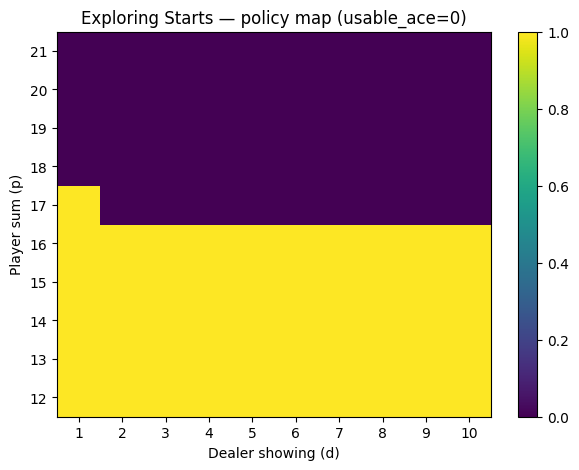

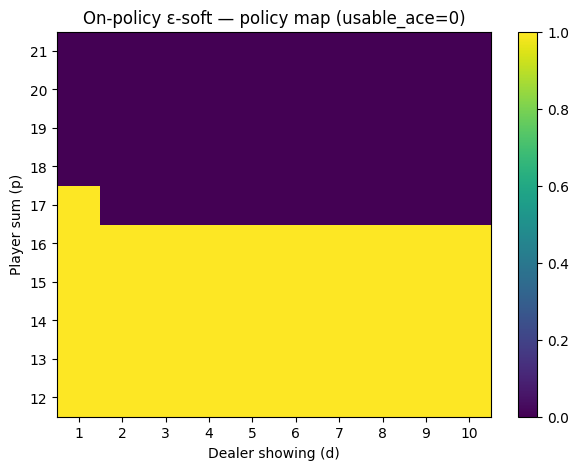

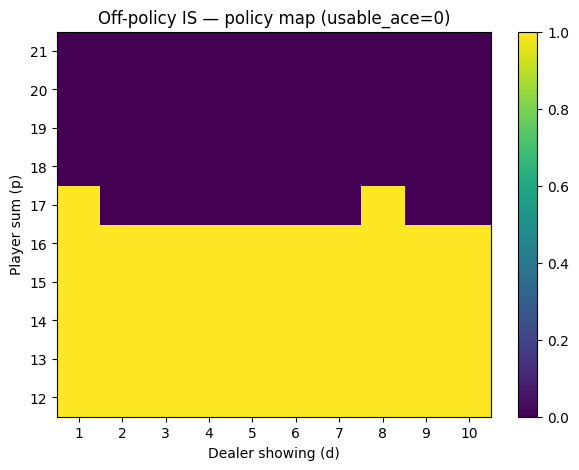

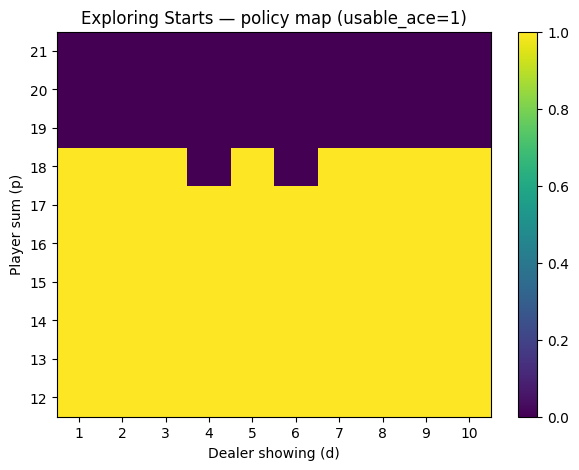

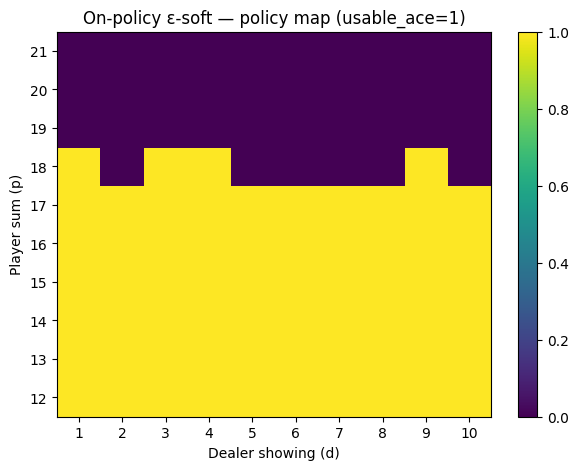

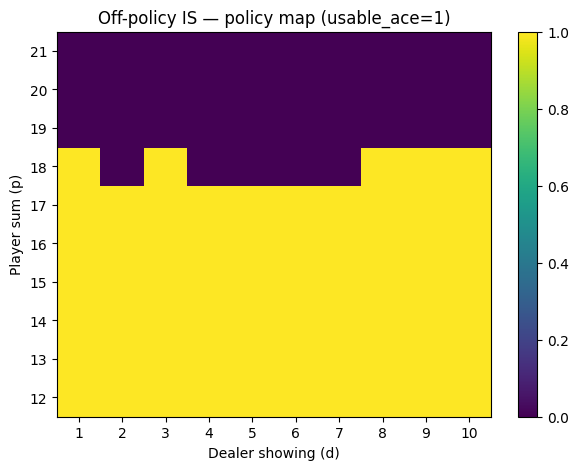

In [ ]:
for usable in [0, 1]:
    for name, pi in policies.items():
        grid_pi = to_grid_from_policy(pi, usable)
        plot_policy_map(grid_pi, title=f"{name} — policy map (usable_ace={usable})")


We now perform a **quantitative comparison** of the greedy policies
learned by the different Monte Carlo control methods.

For two policies $\pi_1$ and $\pi_2$, we define the **policy agreement rate** as the
fraction of states in which both policies choose the **same action**:
$$
\text{Agreement}(\pi_1,\pi_2)
= \frac{1}{|\mathcal S|}
\sum_{s \in \mathcal S}
\mathbf{1}\{\pi_1(s) = \pi_2(s)\}.
$$

The state space considered here includes all Blackjack states with:
- player sums $p = 12,\dots,21$,
- dealer showing cards $d = 1,\dots,10$,
- both cases of usable ace ($u \in \{0,1\}$).

An agreement rate close to **1** indicates that two methods have learned **very similar policies**,
while lower values reveal systematic differences in decision-making.



In [ ]:
def policy_agreement(pi_a, pi_b):
    states = [(p,d,u) for u in [0,1] for p in range(12,22) for d in range(1,11)]
    agree = 0
    for s in states:
        a = pi_a.get(s, HIT)
        b = pi_b.get(s, HIT)
        agree += int(a == b)
    return agree / len(states)

names = list(policies.keys())
for i in range(len(names)):
    for j in range(i+1, len(names)):
        a, b = names[i], names[j]
        print(f"Agreement {a} vs {b}: {policy_agreement(policies[a], policies[b]):.3f}")


Agreement Exploring Starts vs On-policy ε-soft: 0.970
Agreement Exploring Starts vs Off-policy IS: 0.980
Agreement On-policy ε-soft vs Off-policy IS: 0.980


**Evaluating the Value Function of the Learned Policies**

The Monte Carlo control algorithms studied so far directly estimate **action-value functions**
$Q(s,a)$ and output a **greedy policy** $\hat{\pi}$.
However, to compare the *quality* of these learned policies, we must evaluate **how good each policy actually is**.

To do this, we perform **Monte Carlo policy evaluation** for each learned policy $\hat{\pi}$.
More precisely, for a fixed policy $\pi$, we estimate its **state-value function**:
$$
V^{\pi}(s) = \mathbb{E}_{\pi}[G \mid S_0 = s],
$$
where \( G \) denotes the terminal return of a Blackjack episode.

We use **first-visit Monte Carlo evaluation** (cf. Exercise 2. but here with another input which is the policy).


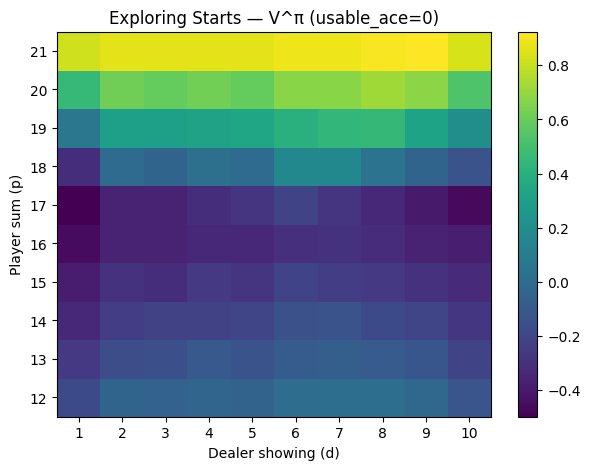

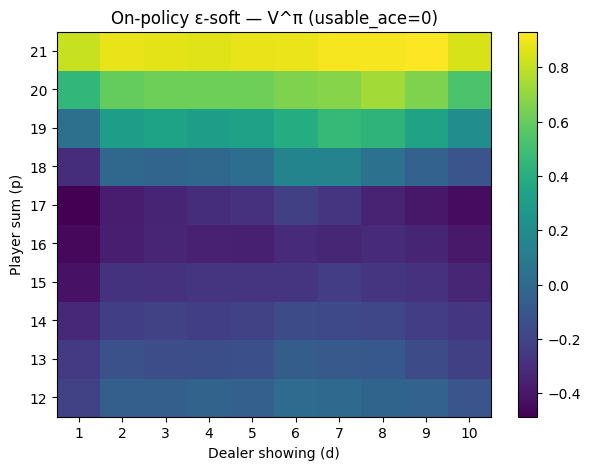

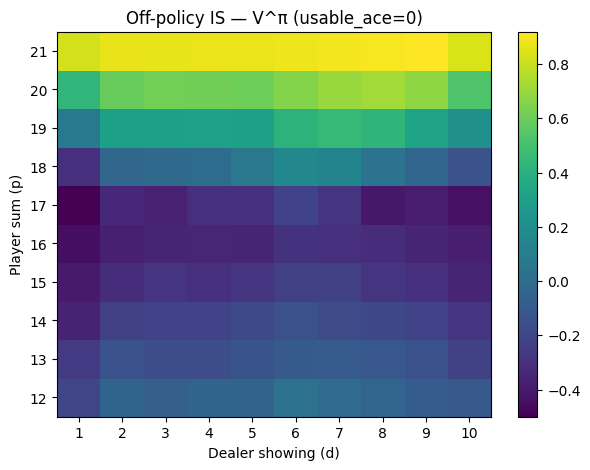

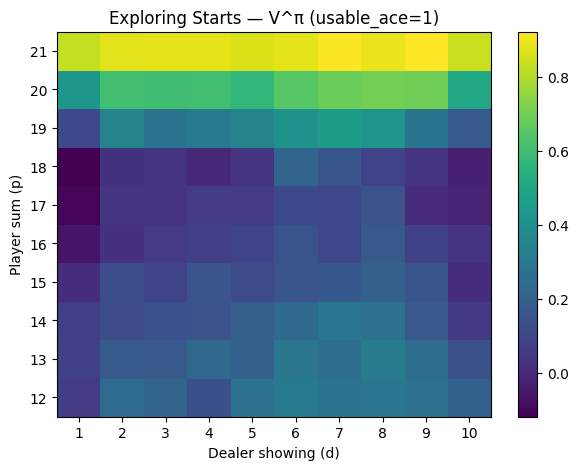

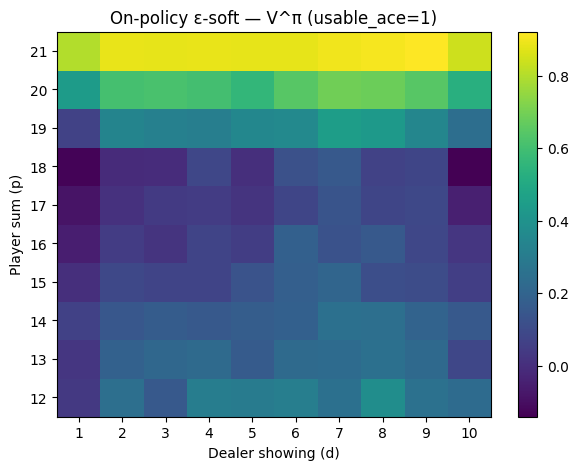

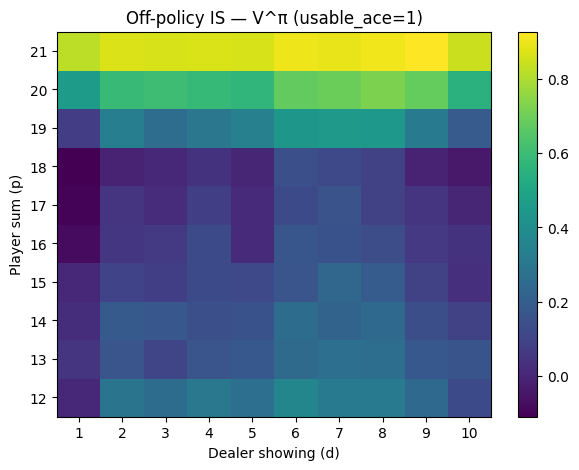

In [ ]:
def mc_policy_evaluation_V(policy, num_episodes=200_000, rng=None):
    """
    First-visit Monte Carlo policy evaluation:
    estimates V^pi(s) for all visited states s.

    policy: dict mapping state->action (HIT/STICK)
    returns: V dict mapping state->value
    """
    if rng is None:
        rng = np.random.default_rng(123)

    returns_sum = defaultdict(float)
    returns_count = defaultdict(int)

    def pi(s):
        return policy.get(s, HIT)

    for _ in range(num_episodes):
        episode, G = generate_episode(pi, rng)  # uses your environment code
        visited = set()

        for (s, a) in episode:
            p, d, u = s
            if p < 12:
                continue

            if s not in visited:
                visited.add(s)
                returns_sum[s] += G
                returns_count[s] += 1

    V = {s: returns_sum[s] / returns_count[s] for s in returns_sum}
    return V


rng_eval = np.random.default_rng(999)

V_of_policy = {}
for name, pi in policies.items():
    V_of_policy[name] = mc_policy_evaluation_V(pi, num_episodes=300_000, rng=rng_eval)

for usable in [0, 1]:
    for name, V in V_of_policy.items():
        grid_V = to_grid_from_V(V, usable)
        plot_value_heatmap(grid_V, title=f"{name} — V^π (usable_ace={usable})")
